# Support Intent Routing Benchmark

**Strong source-test scores did not transfer to newly written requests.** TF-IDF achieved 99.64% macro-F1 on the grouped source test, but 58.89% forced-choice accuracy on 180 supported challenge requests. Frozen MiniLM embeddings with a fitted linear classifier reached 84.44% on that challenge. At their fixed thresholds, they accepted only 30/180 and 60/180 supported challenge requests respectively.

This notebook recomputes tables from saved final predictions, plots recorded measurements, displays 20 predetermined failure cases, and **actually refits the selected TF-IDF pipeline on the frozen training data**. It does not rerun MiniLM or Qwen inference, retune thresholds, or claim that this notebook freshly measured the recorded latency/resource figures. All code cells have saved outputs from execution.

[Audited dataset](https://www.kaggle.com/datasets/dhruvb2028/support-intent-routing-audited-evaluation) | [Repository](https://github.com/dhruvb2028/support-intent-routing-benchmark)

The task is request-only classification into 27 customer-support intents, with abstention on ambiguous or unsupported requests. Bitext's source is hybrid synthetic data; the additional challenge is AI-authored. Neither establishes performance on production customer traffic. This project and its independent review were implemented with AI-agent assistance; independent AI review is not human annotation.


## Data and frozen protocol

The original 26,872 Bitext rows were reduced to 23,826 by canonical deduplication, then organized into 22,445 conservative near-duplicate groups. Training/validation/test contain 16,681 / 3,575 / 3,570 requests. Two punctuation normalization rules are checked independently. Original generation-family IDs are unavailable, so remaining template similarity is a limitation.

Only request text is an input. Labels, identifiers, response text, category and flags are not features. Configurations were selected on validation data; abstention thresholds used a declared utility on corpus validation plus the **separate 60-row development challenge**. The 300-row final challenge has 180 supported, 60 ambiguous, 30 near-domain unsupported and 30 far-domain unsupported examples. It was frozen before final model evaluation.

Models: majority prior; word/character TF-IDF + logistic regression; frozen `all-MiniLM-L6-v2` embeddings + logistic regression; `Qwen2.5-1.5B-Instruct` with one fixed zero-shot prompt and constrained 27-way single-token scoring. MiniLM and Qwen weights were not fine-tuned. The Qwen result applies to this specific prompt and scoring setup, not LLM classifiers generally. Its scores are normalized among the allowed intent tokens and are not calibrated support probabilities.


In [1]:
import base64, hashlib, io, json, zlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import accuracy_score, f1_score

encoded_payload = '...'
raw = zlib.decompress(base64.b64decode(encoded_payload))
assert hashlib.sha256(raw).hexdigest() == 'b8bb90e21047cbe82bd5b0506f4b28b010e778f8319bfc399dbe80754f0d195d'
evidence = json.loads(raw)
models = evidence['benchmark']['models']
names = ['majority','tfidf','minilm','qwen']
pretty = {'majority':'Majority prior','tfidf':'TF-IDF + logistic','minilm':'MiniLM + logistic','qwen':'Qwen fixed zero-shot'}
predictions = {n:{split:pd.read_csv(io.StringIO(evidence['predictions'][n][split])) for split in ['test','challenge_test']} for n in names}
print('Embedded recorded evidence integrity verified.')
print('Frozen selection SHA-256:', evidence['benchmark']['frozen_selection_sha256'])
print('Pinned data sizes:', {k:v['rows'] for k,v in evidence['data_manifest']['splits'].items()})


Embedded recorded evidence integrity verified.
Frozen selection SHA-256: 5dd505704228aff925c118927ff43358180c61cfe6e3d8e575b5de94ee406c0c
Pinned data sizes: {'train': 16681, 'validation': 3575, 'test': 3570}


## Verify the reported metrics from saved predictions

The following computation independently reconstructs source-test accuracy/macro-F1, acceptance coverage and challenge slice rejection rates. It checks reported values rather than copying a headline. A `True` acceptance decision means confidence was at least the already-frozen threshold. No threshold is selected here.


In [2]:
summary=[]; slice_rows=[]
def accepted(frame):
    if frame.accepted.dtype == bool: return frame.accepted.to_numpy()
    return frame.accepted.astype(str).str.lower().eq('true').to_numpy()
def verify_close(actual, reported):
    assert np.isclose(actual, reported, atol=1e-12), (actual, reported)
for name in names:
    m=models[name]; t=predictions[name]['test']; c=predictions[name]['challenge_test']
    acc=accuracy_score(t.label,t.predicted_label)
    f1=f1_score(t.label,t.predicted_label,labels=m['test']['labels'],average='macro',zero_division=0)
    verify_close(acc,m['test']['accuracy']);verify_close(f1,m['test']['macro_f1'])
    ta=accepted(t);verify_close(ta.mean(),m['test']['selective']['coverage'])
    supported=c[c.kind.eq('supported')]; sa=accepted(supported)
    forced=accuracy_score(supported.label,supported.predicted_label)
    verify_close(forced,m['challenge_test']['supported']['accuracy_without_abstention'])
    verify_close(sa.mean(),m['challenge_test']['supported']['coverage'])
    accepted_correct=int((supported.label.to_numpy()[sa]==supported.predicted_label.to_numpy()[sa]).sum())
    for slice_name,mask in [('ambiguous',c.kind.eq('ambiguous')),('near_domain',c.ood_subtype.eq('near_domain')),('far_domain',c.ood_subtype.eq('far_domain'))]:
        subset=c[mask];deferred=int((~accepted(subset)).sum());rate=deferred/len(subset)
        declared=m['challenge_test']['ambiguous_defer_rate'] if slice_name=='ambiguous' else m['challenge_test']['out_of_domain_by_subtype'][slice_name]['defer_rate']
        verify_close(rate,declared)
        slice_rows.append({'Model':pretty[name],'Slice':slice_name,'Deferred':deferred,'Total':len(subset),'Defer %':rate*100})
    ci=m['test']['macro_f1_ci95']
    summary.append({'Model':pretty[name],'Device':m['device'],'Source test macro-F1 %':100*f1,'F1 95% CI':f"{100*ci['low']:.2f}-{100*ci['high']:.2f}",'Challenge supported accuracy %':100*forced,'Challenge accepted':f'{int(sa.sum())}/{len(supported)}','Accepted correct':f'{accepted_correct}/{int(sa.sum())}' if sa.any() else 'N/A (none accepted)','Warm median ms':m['latency']['median_ms'],'Warm p95 ms':m['latency']['p95_ms'],'Threshold':m['selected_config']['threshold']})
summary=pd.DataFrame(summary)
display(summary.round(3))
print('All reconstructed point metrics agree with recorded final metrics.')


,Model,Device,Source test macro-F1 %,F1 95% CI,Challenge supported accuracy %,Challenge accepted,Accepted correct,Warm median ms,Warm p95 ms,Threshold
0,Majority prior,cpu,0.297,0.25-0.35,3.889,0/180,N/A (none accepted),0.329,0.621,0.10
1,TF-IDF + logistic,cpu,99.640,99.42-99.83,58.889,30/180,29/30,1.955,2.764,0.89
2,MiniLM + logistic,cuda,99.423,99.14-99.65,84.444,60/180,60/60,5.957,8.360,0.89
3,Qwen fixed zero-shot,cuda,27.751,26.50-28.86,35.556,0/180,N/A (none accepted),46.302,50.434,1.00


All reconstructed point metrics agree with recorded final metrics.


Source-test confidence intervals use a paired group bootstrap with 1,000 resamples. Challenge intervals are approximate Wilson intervals and assume independent examples; shared synthetic authorship may violate that assumption. The majority and Qwen development-selected thresholds defer every request, so 100% unsupported rejection for those models comes with zero useful coverage. Accepted accuracy is undefined when nothing is accepted.


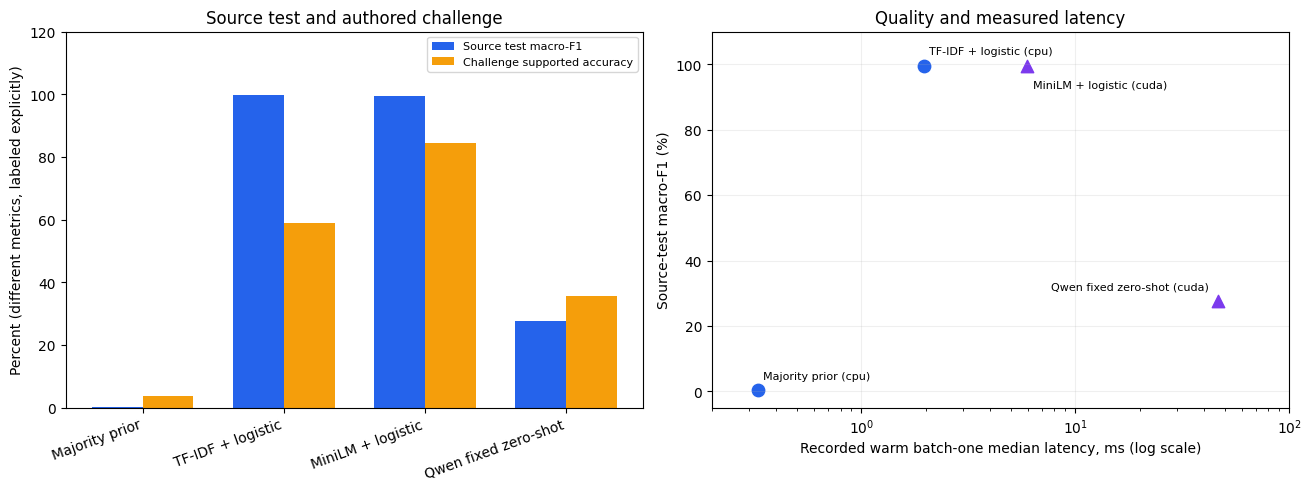

In [3]:
fig,axes=plt.subplots(1,2,figsize=(13,4.8),constrained_layout=True)
x=np.arange(len(names));width=.36
axes[0].bar(x-width/2,[100*models[n]['test']['macro_f1'] for n in names],width,label='Source test macro-F1',color='#2563eb')
axes[0].bar(x+width/2,[100*models[n]['challenge_test']['supported']['accuracy_without_abstention'] for n in names],width,label='Challenge supported accuracy',color='#f59e0b')
axes[0].set_xticks(x,[pretty[n] for n in names],rotation=20,ha='right');axes[0].set_ylim(0,120)
axes[0].set_ylabel('Percent (different metrics, labeled explicitly)');axes[0].set_title('Source test and authored challenge');axes[0].legend(fontsize=8)
for n in names:
    m=models[n]; px=m['latency']['median_ms'];py=100*m['test']['macro_f1']
    axes[1].scatter(px,py,s=80,marker='o' if m['device']=='cpu' else '^',color='#2563eb' if m['device']=='cpu' else '#7c3aed')
    axes[1].annotate(pretty[n]+' ('+m['device']+')',(px,py),xytext=(-6 if n=='qwen' else 4,8 if n!='minilm' else -16),ha='right' if n=='qwen' else 'left',textcoords='offset points',fontsize=8)
axes[1].set_xscale('log');axes[1].set_xlim(.2,100);axes[1].set_ylim(-5,110)
axes[1].set_xlabel('Recorded warm batch-one median latency, ms (log scale)');axes[1].set_ylabel('Source-test macro-F1 (%)');axes[1].set_title('Quality and measured latency');axes[1].grid(alpha=.2)
plot_dir=Path('results/figures');plot_dir.mkdir(parents=True,exist_ok=True)
fig.savefig(plot_dir/'quality-latency.png',dpi=180,bbox_inches='tight')
plt.show()


Warm timings are recorded measurements on one Windows machine, using an NVIDIA GeForce RTX 5060 Laptop GPU for MiniLM/Qwen and CPU execution for the classical models. They use 100 sequential requests, batch size 1, concurrency 1, five warmups and CUDA synchronization. They include preprocessing, tokenization, forward execution and score conversion, but exclude model loading and HTTP. Different devices and runtime stacks limit architecture-only speed comparisons. These timings are not service latency guarantees.


## Abstention and near-domain unsupported requests

Product compatibility, warranty repairs, stock availability and loyalty points are outside the 27-intent ontology. They are evaluated separately from distant knowledge/creative requests. Near-domain rejection did not fail more often than distant rejection in this small challenge; the data does not support claiming otherwise.

At threshold 0.89, TF-IDF accepted 30/180 supported requests and got 29 right, while MiniLM accepted 60/180 and got all 60 right. Their supported coverage was 16.67% and 33.33%. This is a substantial usability cost. Neither high accepted accuracy nor high rejection alone establishes deployment readiness.


In [4]:
display(pd.DataFrame(slice_rows).round(2))
coverage_rows=[]
for n in names:
    m=models[n]['challenge_test'];s=m['supported'];ci=s['selective_accuracy_ci95']
    coverage_rows.append({'Model':pretty[n],'Supported coverage %':s['coverage']*100,'Coverage 95% CI':f"{s['coverage_ci95']['low']*100:.1f}-{s['coverage_ci95']['high']*100:.1f}",'Accepted accuracy %':None if s['selective_accuracy'] is None else s['selective_accuracy']*100,'Accepted accuracy 95% CI':'N/A' if ci is None else f"{ci['low']*100:.1f}-{ci['high']*100:.1f}",'Ambiguous accepted':int(round(60*(1-m['ambiguous_defer_rate'])))})
display(pd.DataFrame(coverage_rows).round(2))


,Model,Slice,Deferred,Total,Defer %
0,Majority prior,ambiguous,60,60,100.00
1,Majority prior,near_domain,30,30,100.00
2,Majority prior,far_domain,30,30,100.00
3,TF-IDF + logistic,ambiguous,52,60,86.67
4,TF-IDF + logistic,near_domain,30,30,100.00
5,TF-IDF + logistic,far_domain,29,30,96.67
6,MiniLM + logistic,ambiguous,53,60,88.33
7,MiniLM + logistic,near_domain,30,30,100.00
8,MiniLM + logistic,far_domain,30,30,100.00
9,Qwen fixed zero-shot,ambiguous,60,60,100.00


,Model,Supported coverage %,Coverage 95% CI,Accepted accuracy %,Accepted accuracy 95% CI,Ambiguous accepted
0,Majority prior,0.00,0.0-2.1,NaN,N/A,0
1,TF-IDF + logistic,16.67,11.9-22.8,96.67,83.3-99.4,8
2,MiniLM + logistic,33.33,26.9-40.5,100.00,94.0-100.0,7
3,Qwen fixed zero-shot,0.00,0.0-2.1,NaN,N/A,0


## Twenty recorded TF-IDF failures

These are the 20 highest-confidence diagnostic errors under the predeclared ordering, selected from source test and challenge together. A `classification_error` means the forced-choice label was wrong, including cases that the threshold correctly deferred. An `unsafe_request_accepted` means an ambiguous or unsupported request was actually accepted. The acceptance column keeps those consequences distinct. The complete per-model failure and prediction files are in the repository.


In [5]:
failures=pd.read_csv(io.StringIO(evidence['failure_cases']['tfidf']))
assert len(failures)==20 and failures.failure.astype(str).str.lower().eq('true').all()
with pd.option_context('display.max_colwidth',120,'display.max_rows',25):
    display(failures[['split','example_id','text','label','predicted_label','confidence','accepted','failure_type']].round({'confidence':4}))


,split,example_id,text,label,predicted_label,confidence,accepted,failure_type
0,challenge_test,challenge_test_180,I need to cancel my order and delete my account.,__abstain__,delete_account,0.9964,True,unsafe_request_accepted
1,challenge_test,challenge_test_186,Can you check the refund status and the shipment status?,__abstain__,track_refund,0.9689,True,unsafe_request_accepted
2,challenge_test,challenge_test_043,How many days do I have to ask for my money back?,check_refund_policy,get_refund,0.9653,True,classification_error
3,challenge_test,challenge_test_184,Please stop the newsletter and reset my forgotten password.,__abstain__,recover_password,0.9618,True,unsafe_request_accepted
4,challenge_test,challenge_test_182,I want a refund and to leave a review.,__abstain__,review,0.9596,True,unsafe_request_accepted
5,challenge_test,challenge_test_232,Please help with the address.,__abstain__,change_shipping_address,0.9392,True,unsafe_request_accepted
6,challenge_test,challenge_test_191,Check the fee for cancellation and the usual delivery time.,__abstain__,check_cancellation_fee,0.9321,True,unsafe_request_accepted
7,challenge_test,challenge_test_188,Tell me your payment methods and your refund rules.,__abstain__,check_payment_methods,0.9284,True,unsafe_request_accepted
8,challenge_test,challenge_test_189,Change my current delivery address and send my invoice.,__abstain__,change_shipping_address,0.9280,True,unsafe_request_accepted
9,challenge_test,challenge_test_241,Write a poem about a sleeping fox.,__abstain__,review,0.9041,True,unsafe_request_accepted


## Operational resource measurements

The following are separate fresh-process probes, not training cost estimates. They use one request per model with downloaded assets already present; filesystem/OS caches may be warm. The probe imports PyTorch and common benchmark dependencies for every model, including CPU models. Baseline RSS and the peak increment are shown alongside total sampled RSS. This is benchmark-process memory, not the minimum memory of an optimized TF-IDF deployment. CUDA peaks are framework allocation/reservation measurements, not total system GPU utilization. One cold run cannot establish a latency distribution.


In [6]:
resource_rows=[]
for n,r in evidence['resources']['models'].items():
    resource_rows.append({'Model':pretty.get(n,n),**{k:r.get(k) for k in ['artifact_deserialization_ms','first_request_ms_including_lazy_weights','model_load_plus_first_request_ms','fresh_process_to_first_result_ms','baseline_rss_mib','peak_sampled_rss_mib','peak_rss_increment_mib','cuda_peak_allocated_mib','cuda_peak_reserved_mib']}})
resource_table=pd.DataFrame(resource_rows).round(2)
display(resource_table[['Model','artifact_deserialization_ms','first_request_ms_including_lazy_weights','model_load_plus_first_request_ms','fresh_process_to_first_result_ms']])
display(resource_table[['Model','baseline_rss_mib','peak_sampled_rss_mib','peak_rss_increment_mib','cuda_peak_allocated_mib','cuda_peak_reserved_mib']])
print('Single-run fresh-process probe; downloaded model assets already cached. Source SHA-256:', evidence['source_hashes']['results/resource_usage.json'])


,Model,artifact_deserialization_ms,first_request_ms_including_lazy_weights,model_load_plus_first_request_ms,fresh_process_to_first_result_ms
0,Majority prior,25.23,17.79,43.02,3083.17
1,TF-IDF + logistic,144.66,3.53,148.19,3263.44
2,MiniLM + logistic,79.51,5277.64,5357.15,9321.13
3,Qwen fixed zero-shot,56.04,8474.50,8530.54,11462.03


,Model,baseline_rss_mib,peak_sampled_rss_mib,peak_rss_increment_mib,cuda_peak_allocated_mib,cuda_peak_reserved_mib
0,Majority prior,582.80,585.20,2.40,NaN,NaN
1,TF-IDF + logistic,584.50,598.08,13.58,NaN,NaN
2,MiniLM + logistic,697.60,1247.32,549.72,96.12,106.0
3,Qwen fixed zero-shot,697.68,6715.57,6017.89,2971.01,3160.0


Single-run fresh-process probe; downloaded model assets already cached. Source SHA-256: 42ff6bb787840a9ba6874c3eceadf6b2da3cc7e6d3885f89163902485e8ac1aa


## Refit the selected TF-IDF pipeline from the published data

This cell performs real training and evaluation. It uses the already-selected C=4 and threshold=0.89, fits all learned text transformations on training only, and checks agreement against the recorded predictions. It does not search configurations or thresholds. Validation is used only for reproduction comparison. The attached dataset is verified by exact file hashes before any training.

Numerical details can vary with package versions; the cell reports actual agreement rather than silently replacing observations with expected scores. The frozen model configurations and published conclusions remain unchanged.


In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import FeatureUnion,Pipeline
from threadpoolctl import threadpool_limits
import sklearn

expected=evidence['data_manifest']['splits']
roots=[Path.cwd()/'data/processed',Path('/kaggle/input/support-intent-routing-audited-evaluation'),Path('/kaggle/input/datasets/dhruvb2028/support-intent-routing-audited-evaluation')]
if Path('/kaggle/input').exists():roots += [p.parent for p in Path('/kaggle/input').rglob('train.csv')]
data_dir=None
for candidate in roots:
    p=candidate/'train.csv'
    if p.is_file() and hashlib.sha256(p.read_bytes()).hexdigest()==expected['train']['sha256']:
        data_dir=candidate;break
if data_dir is None:raise FileNotFoundError('Attach the audited dataset linked above, or run from the repository root with data/processed available.')
frames={}
for split in ['train','validation','test']:
    p=data_dir/f'{split}.csv';assert hashlib.sha256(p.read_bytes()).hexdigest()==expected[split]['sha256']
    frames[split]=pd.read_csv(p)
cp=data_dir/'challenge_test.csv';assert hashlib.sha256(cp.read_bytes()).hexdigest()==models['tfidf']['challenge_test_sha256']
challenge=pd.read_csv(cp)
cfg=evidence['tfidf_selection']['config']
assert cfg['C']==4.0 and cfg['threshold']==.89
replayed=Pipeline([('features',FeatureUnion([
 ('word',TfidfVectorizer(ngram_range=(1,2),sublinear_tf=True,min_df=2,max_features=60000)),
 ('char',TfidfVectorizer(analyzer='char_wb',ngram_range=(3,5),sublinear_tf=True,min_df=2,max_features=100000))])),
 ('classifier',LogisticRegression(C=cfg['C'],solver='lbfgs',max_iter=1500,random_state=cfg['seed']))])
with threadpool_limits(limits=4):
    replayed.fit(frames['train'].text,frames['train'].label)
    vp=replayed.predict_proba(frames['validation'].text)
    tp=replayed.predict_proba(frames['test'].text)
    cp=replayed.predict_proba(challenge.text)
labels=replayed.classes_;test_pred=labels[tp.argmax(axis=1)]
old=predictions['tfidf']['test'].set_index('example_id').loc[frames['test'].example_id]
replay_f1=f1_score(frames['test'].label,test_pred,labels=labels,average='macro',zero_division=0)
report={'scikit_learn':sklearn.__version__,'train_rows':len(frames['train']),'validation_macro_f1':f1_score(frames['validation'].label,labels[vp.argmax(axis=1)],labels=labels,average='macro',zero_division=0),'replayed_test_macro_f1':replay_f1,'recorded_test_macro_f1':models['tfidf']['test']['macro_f1'],'test_label_agreement':float(np.mean(test_pred==old.predicted_label.to_numpy())),'test_acceptance_agreement':float(np.mean((tp.max(axis=1)>=cfg['threshold'])==accepted(old))),'challenge_supported_accuracy':accuracy_score(challenge.loc[challenge.kind.eq('supported'),'label'],labels[cp[challenge.kind.eq('supported')].argmax(axis=1)])}
display(pd.DataFrame([report]).T.rename(columns={0:'Observed value'}))
assert abs(replay_f1-models['tfidf']['test']['macro_f1'])<1e-3,'Reproduction changed materially; inspect runtime differences before using the result.'
print('Actual TF-IDF refit completed with frozen settings; no selection repeated.')


,Observed value
scikit_learn,1.7.2
train_rows,16681
validation_macro_f1,0.997671
replayed_test_macro_f1,0.996396
recorded_test_macro_f1,0.996396
test_label_agreement,1.0
test_acceptance_agreement,1.0
challenge_supported_accuracy,0.588889


Actual TF-IDF refit completed with frozen settings; no selection repeated.


## Reproduce and inspect

In the repository environment:

```bash
python -m pip install -e ".[notebook,test]"
python scripts/prepare_data.py
python -m pytest
python scripts/build_benchmark_notebook.py
```

The report builder requires the recorded result assets and prepared data included with the project. The full test suite also checks the pinned raw source, downloaded by the preparation command. Model artifacts and downloaded weights are not part of a fresh source clone.

For a new complete four-model reproduction, use the launcher to create a separate empty sibling workspace and execute its copied implementation:

```bash
python scripts/start_reproduction.py ../support-router-reproduction --run
```

The destination must not already exist. The launcher performs preparation, selection, freeze and final evaluation with the pinned pretrained weights. It preserves the original evidence. Published test outcomes are already known: this reproduces a known benchmark and is not a new blinded holdout. Do not tune against those outcomes.

After reproduction has produced the required model artifacts, launch its local routing demo with `python ../support-router-reproduction/app.py`. Full neural-model reproduction requires downloaded weights and appropriate compute; the TF-IDF replay above does not require those weights.

## Attribution and limits

Original data: [Bitext Innovations](https://huggingface.co/datasets/bitext/Bitext-customer-support-llm-chatbot-training-dataset), revision `430d1a89bd93bd1fa23c16f29dd53e73f0087443`, CDLA-Sharing-1.0. Prepared corpus data and quoted examples retain that license and attribution. This project changes deduplication, grouping, columns and partitions; it does not claim original collection of Bitext text.

Pretrained weights: [sentence-transformers/all-MiniLM-L6-v2](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/tree/1110a243fdf4706b3f48f1d95db1a4f5529b4d41) and [Qwen/Qwen2.5-1.5B-Instruct](https://huggingface.co/Qwen/Qwen2.5-1.5B-Instruct/tree/989aa7980e4cf806f80c7fef2b1adb7bc71aa306). Original pretrained weights are upstream work; fitted linear classifiers, data/evaluation code and reports are this portfolio's experiment, produced with AI assistance.

The challenge has only 180 supported requests and 30 examples per unsupported subtype. It is English-only, narrow-domain and authored/reviewed by AI agents. Public source data may also appear in pretraining. The thresholds reflect a chosen development utility, not measured production costs or prevalence. No probability calibration, real-traffic validation, financial cost benchmark, training-energy estimate or production-readiness claim is made.
